# 06 Forecasts: demand, trends and online-hiring signals

| Field | Value |
|---|---|
| **Purpose** | Short-horizon forecasts of job demand by category and of the online-hiring signals, with honest uncertainty |
| **Assignment requirement** | **Task 3** (forecast high-demand job categories), **Task 8** (future-trend predictions) and the forecast part of **Task 7** |
| **Inputs** | `forecast_*.csv` from the pipeline's `forecast` step, `trend_category_daily.csv`, `remote_daily.csv` |
| **Outputs** | None; the forecast tables feed the dashboard |
| **Build identity** | Printed by the first code cell |

**How far ahead.** Because the reliable history contains only 37 days, the forecast is limited to a short 14-day horizon (24 March - 6 April 2024). Longer-range forecasts are not supported by enough history. **Days 1-7** are the primary forecast; **days 8-14** are an extended short-term outlook with more uncertainty, because the evaluation below checks 7-day forecasts directly and 14-day forecasts only a few times.

**How the forecasts are made and checked (decision D-033)**

- **Four simple models**, all defined before any evaluation (code and `config/pipeline.toml`):

| Model | Forecast for a future day |
|---|---|
| `seasonal_naive` | the same weekday one week earlier (the standard baseline) |
| `weekday_mean` | the average of that weekday over the last 14 days |
| `trend_weekday` | Notebook 05's straight line plus weekday effects, continued forward |
| `damped_trend` | the same line, but each day ahead keeps only 90% of the previous day's trend, so a short-lived change cannot run away |

- **Development period and reserved window.** The first 30 days (16 February - 16 March) are the development period. The last 7 days (17 - 23 March) are a **reserved final forecast evaluation window**: they are used neither for fitting nor for choosing a model. (They are not "blind" in the sense of the 350 labels: Notebook 05 already describes all 37 days.)
- **Rolling-origin backtest.** Inside the development period, the models repeatedly pretend it is an earlier day (after 14, 15, ... 23 days), forecast the next 7 days and are compared with what happened.
- **Two model families, one winner each.** *Demand* (total jobs and the 23 category series) and *signals* (Task 7: hourly share, North American client share, concentration). Each family gets the single model with the lowest average error over all its series. No category gets a hand-picked model: that would overfit.
- **Coherent demand.** Total jobs and category shares are forecast with the same model; shares are kept between 0 and 1 and rescaled to add up to 100%; category jobs = total x share. So the 22 categories plus Other always add up to the total.

**Error measures**

- **MAE**: the average absolute error, in the series' own units (jobs per day, or share points).
- **Seasonal MASE**: MAE divided by the typical week-on-week change *in the training data*. It makes errors comparable across series of very different sizes; the family winner is chosen on this measure.
- **Relative MAE**: the model's MAE divided by the seasonal-naive baseline's MAE on the same days. **Below 1 beats the baseline**, 1 ties it, above 1 is worse.
- No MAPE: small category counts make percentage errors unstable.

In [1]:
from job_market.notebook import start

project = start()

RUN_ID: 20261005T085046Z-90e95d23f3
Source: data/raw/all_upwork_jobs_2024-02-07-2024-03-24.csv (244,828 rows)
Taxonomy version: 1.0
Verified outputs: 53 file(s), all hashes match
Environment: matches environment.yml


In [2]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from job_market.taxonomy import CATEGORIES, OTHER

pd.set_option("display.max_colwidth", 50)
pd.set_option("display.width", 170)

choice = project.read_csv("forecast_model_choice.csv")
by_series = project.read_csv("forecast_backtest_by_series.csv")
long_check = project.read_csv("forecast_backtest_14d.csv")
final = project.read_csv("forecast_final_evaluation.csv")
demand_daily = project.read_csv("forecast_demand_daily.csv", parse_dates=["date"])
outlook = project.read_csv("forecast_demand_outlook.csv")
signals_daily = project.read_csv("forecast_signals_daily.csv", parse_dates=["date"])
signals_outlook = project.read_csv("forecast_signals_outlook.csv")
history = project.read_csv("trend_category_daily.csv", parse_dates=["date"])
remote_daily = project.read_csv("remote_daily.csv", parse_dates=["date"])
rules = project.settings.section("forecast")

NAMES = {key: name for key, (name, _) in CATEGORIES.items()}
NAMES["total"] = "All jobs"
winners = choice[choice["chosen"]].set_index("family")["model"]
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#b8b6b0"
plt.rcParams.update({
    "figure.dpi": 110, "axes.edgecolor": MUTED, "axes.labelcolor": INK, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 10, "legend.frameon": False,
})
print(f"Forecast: {demand_daily['date'].min():%d %b} - {demand_daily['date'].max():%d %b %Y}; "
      f"damping {rules['damping_phi']}; winners: demand = {winners['demand']}, signals = {winners['signals']}")

Forecast: 24 Mar - 06 Apr 2024; damping 0.9; winners: demand = weekday_mean, signals = weekday_mean


## 1. Choosing the model: the rolling backtest

Average errors over all series of a family, all 10 backtest origins and forecast days 1-7 (development period only):

In [3]:
choice.round(3)

,family,model,mase,relative_mae,chosen
0,demand,weekday_mean,0.771,1.009,True
1,demand,damped_trend,0.821,1.009,False
2,demand,trend_weekday,0.842,1.040,False
3,demand,seasonal_naive,0.859,1.000,False
4,signals,weekday_mean,0.560,0.959,True
5,signals,damped_trend,0.605,1.007,False
6,signals,seasonal_naive,0.606,1.000,False
7,signals,trend_weekday,0.633,1.049,False


In [4]:
demand_series = by_series[(by_series["family"] == "demand")]
wins = demand_series[demand_series["model"] == winners["demand"]]
print(f"Demand series where {winners['demand']} beats the baseline in development: "
      f"{int((wins['relative_mae'] < 1).sum())} of {len(wins)}")
pivot = demand_series.pivot(index="series", columns="model", values="relative_mae")
pivot.index = pivot.index.map(NAMES)
pivot.round(2).sort_values(winners["demand"])

Demand series where weekday_mean beats the baseline in development: 17 of 24


model,damped_trend,seasonal_naive,trend_weekday,weekday_mean
series,,,,
Customer Service,1.06,1.0,1.11,0.62
Mobile Development,0.78,1.0,0.80,0.63
Video & Animation,0.94,1.0,1.00,0.70
Software & IT,0.78,1.0,0.79,0.71
Legal,0.73,1.0,0.75,0.72
Audio & Music,1.00,1.0,1.02,0.78
Engineering & Architecture,0.72,1.0,0.73,0.79
Web Development,1.08,1.0,1.13,0.80
Sales & Lead Generation,0.93,1.0,0.94,0.84


**Finding.** In both families the **weekday mean** has the lowest average MASE and is the winner by the rule fixed in advance. Its advantage over the simplest baseline is small: on Relative MAE it ties the same-weekday baseline for demand (about 1.01) and is slightly better for the signals (about 0.96). The two trend models do worse: carrying a line forward from five weeks of data adds error. This is the warning from Notebook 05 in numbers: part of the trends there is an early step, and a trend model extends it into the future.

**Secondary check: 14 days ahead.** Only 3 backtest origins leave room for 14 forecast days inside the development period, so this is a rough check of days 8-14, not a full evaluation:

In [5]:
long_check.round(3)

,family,model,mase,relative_mae,origins
0,demand,weekday_mean,0.827,1.040,3
1,demand,seasonal_naive,0.866,1.000,3
2,demand,damped_trend,0.927,1.110,3
3,demand,trend_weekday,1.070,1.319,3
4,signals,weekday_mean,0.491,0.999,3
5,signals,seasonal_naive,0.518,1.000,3
6,signals,damped_trend,0.672,1.331,3
7,signals,trend_weekday,0.991,1.988,3


The ranking at days 8-14 is the same: the weekday mean is best, and the straight trend becomes clearly worse the farther it is carried.

## 2. The reserved final window (17 - 23 March)

The models, exactly as defined, are fitted on the development period and scored once on the last 7 days:

In [6]:
summary_final = final.groupby(["family", "model"])[["mase", "relative_mae"]].mean().round(3)
summary_final["chosen"] = [winners[f] == m for f, m in summary_final.index]
summary_final

mase  relative_mae  chosen
family  model                                      
demand  damped_trend    0.828         0.860   False
        seasonal_naive  0.987         1.000   False
        trend_weekday   0.840         0.874   False
        weekday_mean    0.836         0.868    True
signals damped_trend    0.505         0.770   False
        seasonal_naive  0.627         1.000   False
        trend_weekday   0.527         0.793   False
        weekday_mean    0.559         0.976    True

In [7]:
cats_final = final[(final["family"] == "demand") & (final["series"] != "total") & (final["model"] == winners["demand"])]
beats_final = int((cats_final["relative_mae"] < 1).sum())
print(f"Category series (22 + Other) where the winner beats the baseline in the final window: {beats_final} of {len(cats_final)}")
final[(final["series"] == "total")].round(3)

Category series (22 + Other) where the winner beats the baseline in the final window: 20 of 23


,family,model,series,mae,mase,relative_mae,chosen
0,demand,seasonal_naive,total,72.143,0.389,1.000,False
24,demand,weekday_mean,total,112.000,0.603,1.552,True
48,demand,trend_weekday,total,108.084,0.582,1.498,False
72,demand,damped_trend,total,115.188,0.621,1.597,False


In [8]:
final[final["family"] == "signals"].pivot(index="series", columns="model", values="relative_mae").round(3)

model,damped_trend,seasonal_naive,trend_weekday,weekday_mean
series,,,,
hhi,0.787,1.0,0.787,1.150
hourly_share,0.899,1.0,0.967,0.653
north_america_share,0.623,1.0,0.625,1.125


**Finding.**

- For the **categories**, the weekday mean beats the baseline in the final window for **20 of 23** series (average Relative MAE about **0.84**). All three non-naive models do similarly well here; the choice between them matters little.
- For **total jobs**, the same-weekday baseline is clearly better than every other model (Relative MAE about 1.5 for the others). The total volume moves in a way the weekly average smooths away. Because the demand forecast must be coherent, the total uses the family winner anyway; this is a known cost of the one-model rule and is reported, not hidden.
- For the **signals**, the winner beats the baseline for the hourly share but not for the North American share or concentration, where the trend models happen to do best in this one week. A single week is too little to overturn the backtest choice; this is exactly why the choice was made on the development period.

## 3. Task 3: which categories will be in highest demand?

Expected jobs per day for each category over the forecast period, from the winning model refitted on all 37 days. The ranges are **empirical 80% forecast ranges**: they come from the model's own backtest errors at each horizon (standardised by each series' typical weekly change), so they widen farther ahead. Beyond day 7 they are widened by a fixed rule (square root of the horizon ratio), because day-8-14 errors were barely observed. The weekly figures average the daily ranges: they describe a typical day, not the weekly total.

In [9]:
ranking = outlook[outlook["series"] != "total"].sort_values("rank_1_7").copy()
ranking["name"] = ranking["series"].map(NAMES)
ranking["range overlaps next rank"] = (ranking["low_1_7"] <= ranking["high_1_7"].shift(-1)).map({True: "yes", False: ""})
ranking[["rank_1_7", "name", "recent_jobs_per_day", "forecast_jobs_per_day_1_7", "low_1_7", "high_1_7",
         "forecast_jobs_per_day_8_14", "low_8_14", "high_8_14", "range overlaps next rank"]].set_index("rank_1_7").round(1)

,name,recent_jobs_per_day,forecast_jobs_per_day_1_7,low_1_7,high_1_7,forecast_jobs_per_day_8_14,low_8_14,high_8_14,range overlaps next rank
rank_1_7,,,,,,,,,
1.0,Web Development,899.3,897.4,845.5,950.7,897.4,840.4,964.1,
2.0,Other / Unclear,770.9,758.5,711.3,806.9,758.5,706.7,819.0,yes
3.0,Design & Creative,714.4,716.3,664.1,769.9,716.3,658.9,783.4,yes
4.0,Digital Marketing,646.9,662.8,616.8,710.1,662.8,612.3,721.9,
5.0,Software & IT,468.0,465.2,434.4,496.7,465.2,431.4,504.6,yes
6.0,Video & Animation,411.4,420.2,387.6,453.6,420.2,384.4,462.0,
7.0,Writing & Content,245.0,257.2,197.3,318.7,257.2,191.4,334.1,yes
8.0,Sales & Lead Generation,253.9,250.4,224.2,277.2,250.4,221.6,284.0,yes
9.0,Admin & Virtual Assistance,224.7,227.7,173.5,283.2,227.7,168.2,297.1,yes


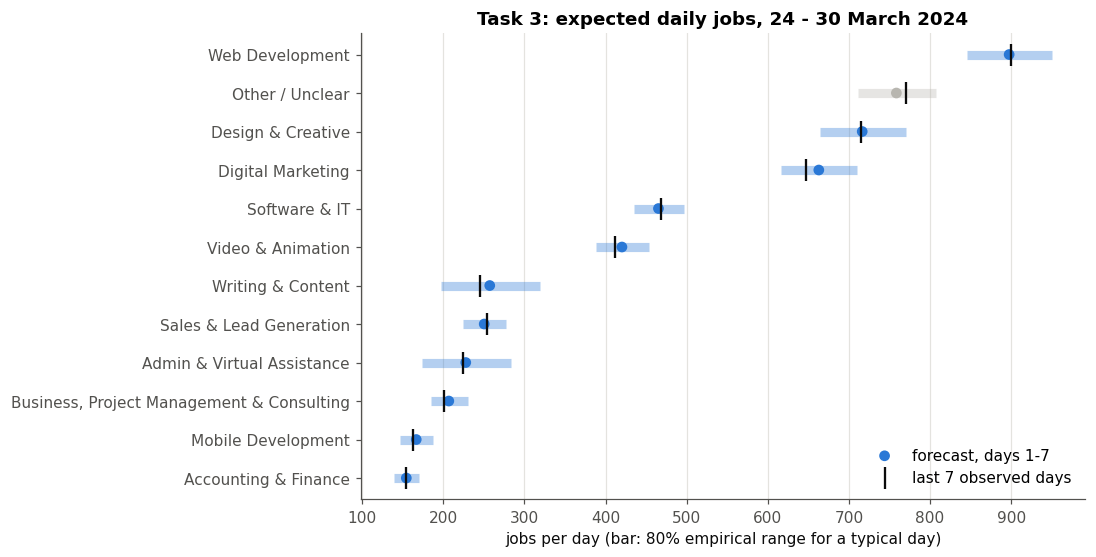

In [10]:
show = ranking.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(8.5, 5.5))
y = np.arange(len(show))
colors = [GREY if s == OTHER else BLUE for s in show["series"]]
ax.hlines(y, show["low_1_7"], show["high_1_7"], color=colors, lw=6, alpha=0.35)
ax.scatter(show["forecast_jobs_per_day_1_7"], y, color=colors, zorder=3, label="forecast, days 1-7")
ax.scatter(show["recent_jobs_per_day"], y, marker="|", s=200, color=INK, zorder=4, label="last 7 observed days")
ax.set_yticks(y)
ax.set_yticklabels(show["name"])
ax.set_xlabel("jobs per day (bar: 80% empirical range for a typical day)")
ax.set_title("Task 3: expected daily jobs, 24 - 30 March 2024")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
plt.show()

**Finding.** In the next one to two weeks, **Web Development** stays the largest function (about 900 jobs a day), followed by **Design** (about 715) and **Digital Marketing** (about 665), then **Software & IT** and **Video**. *Other / Unclear* is large too (about 760 a day) and is shown because it is part of the total. Most neighbouring ranks have overlapping ranges, so small rank differences (for example Sales versus Writing, or Admin versus Business) do not mean one is clearly more in demand. The forecast is close to the last observed week: with five weeks of history, the honest expectation for the next two weeks is "about the same as now, adjusted for the weekday".

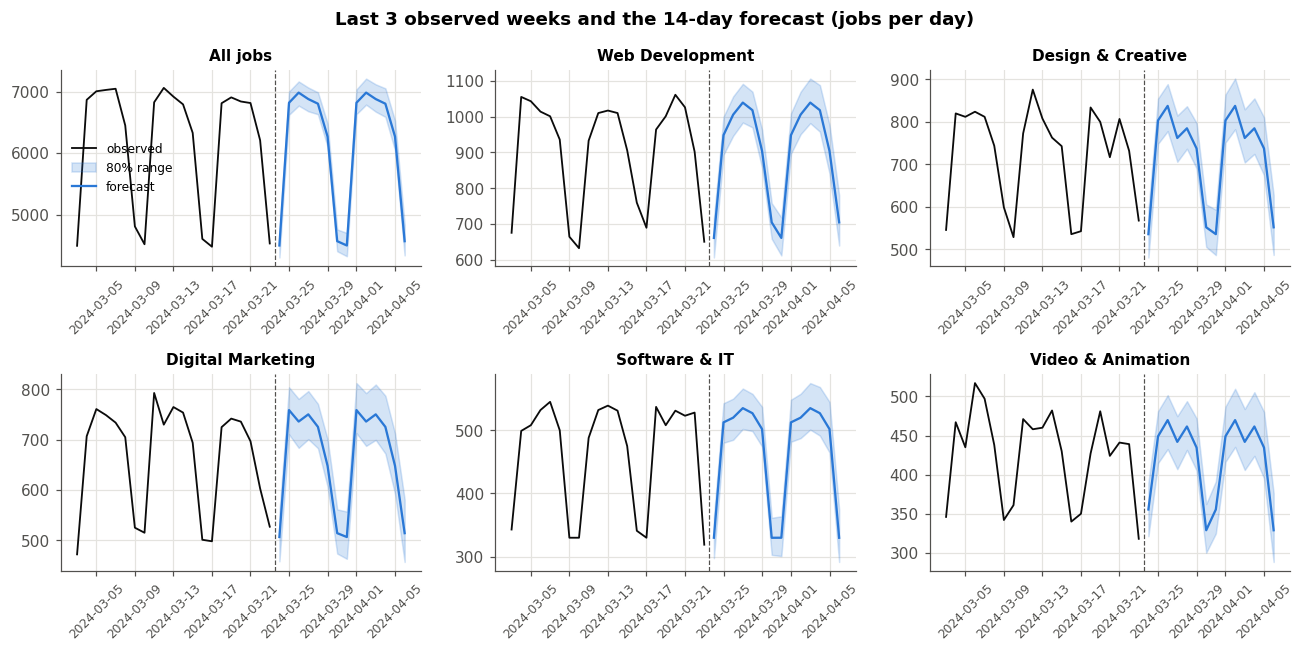

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, series in zip(axes.flat, ["total", "web_development", "design_creative", "digital_marketing", "software_it", "video_animation"]):
    if series == "total":
        past = history.groupby("date")["jobs"].sum()
    else:
        past = history[history["primary_category"] == series].set_index("date")["jobs"]
    future = demand_daily[demand_daily["series"] == series]
    ax.plot(past.index[-21:], past.values[-21:], color=INK, lw=1.2, label="observed")
    ax.fill_between(future["date"], future["low"], future["high"], color=BLUE, alpha=0.2, label="80% range")
    ax.plot(future["date"], future["forecast"], color=BLUE, lw=1.5, label="forecast")
    ax.axvline(future["date"].min() - pd.Timedelta(hours=12), color=MUTED, lw=0.8, ls="--")
    ax.set_title(NAMES[series], fontsize=10)
    ax.tick_params(axis="x", rotation=45, labelsize=8)
axes.flat[0].legend(fontsize=8)
fig.suptitle("Last 3 observed weeks and the 14-day forecast (jobs per day)", fontweight="bold")
fig.tight_layout()
plt.show()

## 4. Task 8: which trends can be expected to continue?

For each category: the **recent observed share** (average of the last 7 observed days), the winner's forecast share, and the direction a **trend-style model** projects for the next 14 days. A direction is reported **only if** the better trend-style model (straight or damped trend) beat the same-weekday baseline for that category in the development backtest. Otherwise the table says **"no reliable direction"** instead of forcing "rising" or "falling". A projected change smaller than 0.1 percentage points is called "stable".

In [12]:
trend = outlook[outlook["series"] != "total"].copy()
trend["name"] = trend["series"].map(NAMES)
direction_counts = trend["direction"].value_counts()
print(direction_counts.to_string())
trend[["name", "recent_share_pct", "forecast_share_pct_1_7", "forecast_share_pct_1_14", "trend_model",
       "trend_model_relative_mae", "trend_share_pct_1_14", "trend_change_pp", "direction"]].sort_values(
    ["direction", "trend_change_pp"]).set_index("name").round(3)

direction
no reliable direction    10
stable                    9
rising                    4


,recent_share_pct,forecast_share_pct_1_7,forecast_share_pct_1_14,trend_model,trend_model_relative_mae,trend_share_pct_1_14,trend_change_pp,direction
name,,,,,,,,
Writing & Content,4.023,4.205,4.205,damped_trend,1.228,3.465,-0.557,no reliable direction
Admin & Virtual Assistance,3.674,3.711,3.711,damped_trend,1.145,3.211,-0.463,no reliable direction
Translation & Transcription,1.435,1.587,1.587,damped_trend,1.287,1.225,-0.210,no reliable direction
Other / Unclear,12.665,12.386,12.386,damped_trend,1.097,12.482,-0.183,no reliable direction
Customer Service,1.195,1.062,1.062,damped_trend,1.064,1.086,-0.110,no reliable direction
Data & Analytics,2.457,2.431,2.431,damped_trend,1.184,2.351,-0.107,no reliable direction
Education & Tutoring,1.029,0.990,0.990,damped_trend,1.012,1.002,-0.027,no reliable direction
Audio & Music,1.409,1.415,1.415,damped_trend,1.002,1.399,-0.010,no reliable direction
AI & Machine Learning,1.522,1.491,1.491,trend_weekday,1.410,1.580,0.058,no reliable direction


**Finding.**

- A continuing **rise** is supported for **Digital Marketing**, **Video & Animation**, **Design** and, only marginally, **Business & Project Management** (its trend model beats the baseline by less than 1%). The projected gains are small: up to about +0.5 percentage points of share over two weeks.
- **Writing, Admin and Translation**, the biggest movers in Notebook 05, get **"no reliable direction"**: trend models did *not* beat the baseline for them. This fits Notebook 05's finding that much of their decline was an early step, not a steady slide; projecting it forward is not supported.
- **AI & Machine Learning** also gets "no reliable direction": its share rises, but too noisily for a trend model to beat the baseline.
- Nine categories are projected **stable**.

**What this means for "future trends" (Task 8).** Within a two-week horizon, the data supports modest continued growth in marketing, video and design work, and nothing stronger. Longer-term claims ("AI jobs will double", "writing jobs will disappear") cannot be supported by five weeks of data, and this project does not make them.

## 5. Task 7: forecasts of the online-hiring signals

Notebook 05 measured three signals with enough data. Their forecasts, with empirical 80% ranges kept inside valid bounds (0 to 1):

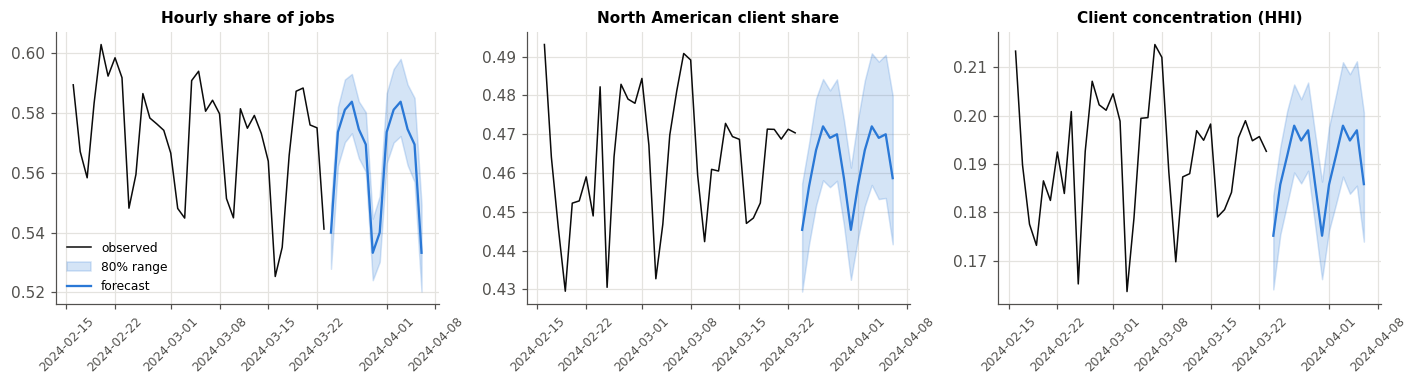

,series,recent_value,forecast_1_7,forecast_1_14,trend_model,trend_model_relative_mae,trend_forecast_1_14,direction
0,hourly_share,0.5670,0.5651,0.5651,damped_trend,1.0844,0.5589,no reliable direction
1,north_america_share,0.4648,0.4625,0.4625,damped_trend,1.0318,0.4654,no reliable direction
2,hhi,0.1917,0.1897,0.1897,damped_trend,0.9037,0.1913,stable


In [13]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
labels = {"hourly_share": "Hourly share of jobs", "north_america_share": "North American client share",
          "hhi": "Client concentration (HHI)"}
for ax, series in zip(axes, labels):
    future = signals_daily[signals_daily["series"] == series]
    ax.plot(remote_daily["date"], remote_daily[series], color=INK, lw=1, label="observed")
    ax.fill_between(future["date"], future["low"], future["high"], color=BLUE, alpha=0.2, label="80% range")
    ax.plot(future["date"], future["forecast"], color=BLUE, lw=1.5, label="forecast")
    ax.set_title(labels[series], fontsize=10)
    ax.tick_params(axis="x", rotation=45, labelsize=8)
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()
signals_outlook.round(4)

**Finding.** All three signals are forecast to stay close to their recent levels: about **57%** of jobs hourly, about **46%** of jobs with a known country from North American clients, and a concentration equal to about **5.2** equally sized countries. No trend-style model beat the baseline for the hourly or North American share, so no direction is claimed; for concentration the projected change is negligible ("stable"). In other words, the slight shift towards fixed-price work seen in Notebook 05 is not strong enough to project forward.

**No forecasts** are made for "remote", "hybrid", on-site mentions or new AI terms: their weekly counts (Notebook 05) are far too small for a defensible forecast.

## 6. Summary

- **Horizon:** 14 days (24 March - 6 April 2024); days 1-7 primary, days 8-14 an extended outlook.
- **Model:** the weekday mean wins both families by the rule fixed in advance; trend models add error at this history length.
- **Reserved final window:** category forecasts beat the baseline for 20 of 23 series; the total does not (the baseline is better there).
- **Task 3:** Web, Design and Marketing remain the highest-demand functions (about 900, 715 and 665 jobs a day); neighbouring ranks often overlap.
- **Task 8:** a modest continuing rise is supported only for Marketing, Video, Design (and marginally Business); the big Notebook 05 movers get "no reliable direction".
- **Task 7:** hourly share, North American share and concentration are forecast to stay about where they are.

**Limits.** Five weeks of history; one week of final evaluation; the collection process is undocumented; categories carry Notebook 03's error (68.9% blind agreement), so category forecasts inherit that uncertainty, and functions often hidden in *Other* (Software, AI, Engineering) are likely undercounted in the forecasts too.

## 7. Claims check

Every number quoted in this notebook's text, checked against the data:

In [14]:
ch = choice.set_index(["family", "model"])
rk = ranking.set_index("series")
so = signals_outlook.set_index("series")
tr = trend.set_index("series")
claims = {
    "horizon 24 Mar - 6 Apr": (demand_daily["date"].min() == pd.Timestamp("2024-03-24")
                               and demand_daily["date"].max() == pd.Timestamp("2024-04-06")),
    "damping 0.9": rules["damping_phi"] == 0.9,
    "weekday mean wins both families": winners["demand"] == "weekday_mean" and winners["signals"] == "weekday_mean",
    "demand relative MAE about 1.01": round(ch.loc[("demand", "weekday_mean"), "relative_mae"], 2) == 1.01,
    "signals relative MAE about 0.96": round(ch.loc[("signals", "weekday_mean"), "relative_mae"], 2) == 0.96,
    "trend models worse than weekday mean": all(ch.loc[("demand", m), "mase"] > ch.loc[("demand", "weekday_mean"), "mase"]
                                               for m in ["trend_weekday", "damped_trend"]),
    "3 origins in the 14-day check": int(long_check["origins"].max()) == 3,
    "14-day check: weekday mean best": long_check.sort_values("mase").groupby("family").head(1)["model"].eq("weekday_mean").all(),
    "final: 20 of 23 categories beat baseline": beats_final == 20 and len(cats_final) == 23,
    "final: category relative MAE about 0.84": round(cats_final["relative_mae"].mean(), 2) == 0.84,
    "final: baseline best for total, others about 1.5": all(1.4 <= v <= 1.65 for v in
        final[(final["series"] == "total") & (final["model"] != "seasonal_naive")]["relative_mae"]),
    "final: winner beats baseline for hourly share only": (
        final[(final["family"] == "signals") & (final["model"] == "weekday_mean")].set_index("series")["relative_mae"].lt(1).to_dict()
        == {"hourly_share": True, "north_america_share": False, "hhi": False}),
    "web about 900, design 715, marketing 665": ([round(rk.loc[s, "forecast_jobs_per_day_1_7"], -1) for s in
                                                  ["web_development", "design_creative", "digital_marketing"]] == [900, 720, 660]),
    "other about 760": round(rk.loc[OTHER, "forecast_jobs_per_day_1_7"], -1) == 760,
    "top 3 named functions: web, design, marketing": list(ranking[ranking["series"] != OTHER]["series"].head(3)) ==
        ["web_development", "design_creative", "digital_marketing"],
    "rising: marketing, video, design, business": set(tr.index[tr["direction"] == "rising"]) ==
        {"digital_marketing", "video_animation", "design_creative", "business_project_management"},
    "business only marginal (relative MAE > 0.99)": tr.loc["business_project_management", "trend_model_relative_mae"] > 0.99,
    "gains up to about +0.5 pp": round(tr.loc[tr["direction"] == "rising", "trend_change_pp"].max(), 1) == 0.5,
    "writing/admin/translation/AI: no reliable direction": all(tr.loc[s, "direction"] == "no reliable direction" for s in
        ["writing_content", "admin_virtual_assistance", "translation_transcription", "ai_ml"]),
    "nine stable": int(direction_counts.get("stable", 0)) == 9,
    "hourly about 57%, NA about 46%, HHI equals about 5.2 countries": (
        round(100 * so.loc["hourly_share", "forecast_1_14"]) == 57 and round(100 * so.loc["north_america_share", "forecast_1_14"]) == 46
        and round(1 / so.loc["hhi", "forecast_1_14"], 1) in (5.2, 5.3)),
    "no direction for hourly and NA share; HHI stable": (so.loc["hourly_share", "direction"] == "no reliable direction"
        and so.loc["north_america_share", "direction"] == "no reliable direction" and so.loc["hhi", "direction"] == "stable"),
}
claims = pd.Series(claims, name="true").to_frame()
assert claims["true"].all(), claims[~claims["true"]]
claims

,true
horizon 24 Mar - 6 Apr,True
damping 0.9,True
weekday mean wins both families,True
demand relative MAE about 1.01,True
signals relative MAE about 0.96,True
trend models worse than weekday mean,True
3 origins in the 14-day check,True
14-day check: weekday mean best,True
final: 20 of 23 categories beat baseline,True
final: category relative MAE about 0.84,True
